# Hillstrom Email Marketing: T-Learner

Experiment 2 estimates heterogeneous effects of **any promotional email** versus **no email** on a website visit. The original randomized study assigned 64,000 customers to Men's E-Mail, Women's E-Mail, or No E-Mail. Pooling both email arms defines the binary treatment, so results concern the policy of sending either email creative. The primary outcome is a website visit during the two weeks after the campaign.

Source: Kevin Hillstrom, [MineThatData E-Mail Analytics and Data Mining Challenge (2008)](https://blog.minethatdata.com/2008/03/minethatdata-e-mail-analytics-and-data.html). This notebook implements only a T-Learner. It reuses the S-Learner experiment's features, 80/20 stratified split, seed, and random-forest parameters for comparison.

In [1]:
from pathlib import Path
import hashlib
import platform
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import auc
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

RANDOM_SEED = 42
TEST_SIZE = 0.20
EXPECTED_SHA256 = "0e5893329d8b93cefecc571777672028290ab69865718020c78c7284f291aece"
DATA_PATH = Path("../data/raw/Kevin_Hillstrom_MineThatData_E-MailAnalytics_DataMiningChallenge_2008.03.20.csv")
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() == EXPECTED_SHA256
print(f"Python {platform.python_version()} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")
print("Dataset SHA-256 verified:", EXPECTED_SHA256)

Python 3.12.15 | pandas 3.1.1 | scikit-learn 1.9.1
Dataset SHA-256 verified: 0e5893329d8b93cefecc571777672028290ab69865718020c78c7284f291aece


## Data validation and design

Pretreatment features are recency, past-year spending and spending segment, prior Men's/Women's purchases, ZIP category, new-customer status, and purchase channel. `segment` encodes randomized assignment. `visit`, `conversion`, and `spend` are outcomes after assignment and are excluded from model inputs.

In [2]:
df = pd.read_csv(DATA_PATH)
feature_cols = ["recency", "history_segment", "history", "mens", "womens", "zip_code", "newbie", "channel"]
numeric_features = ["recency", "history", "mens", "womens", "newbie"]
categorical_features = ["history_segment", "zip_code", "channel"]
df["treatment"] = (df.segment != "No E-Mail").astype(int)
df["outcome"] = df.visit.astype(int)

print("Shape:", df.shape, "| duplicate rows:", df.duplicated().sum())
print("Missing values:", int(df.isna().sum().sum()))
display(df.dtypes.to_frame("dtype"))
display(df.segment.value_counts().rename_axis("original_group").to_frame("count"))
display(df[["visit", "conversion", "spend"]].agg(["count", "mean", "sum", "min", "max"]).T)

balance_x = pd.get_dummies(df[feature_cols], columns=categorical_features, dtype=float)
balance_rows = []
for col in balance_x:
    a, b = balance_x.loc[df.treatment == 1, col], balance_x.loc[df.treatment == 0, col]
    sd = np.sqrt((a.var(ddof=1) + b.var(ddof=1)) / 2)
    balance_rows.append([col, (a.mean() - b.mean()) / sd if sd else 0.0])
balance = pd.DataFrame(balance_rows, columns=["feature", "SMD"])
display(balance.assign(abs_SMD=balance.SMD.abs()).sort_values("abs_SMD", ascending=False).head(5).round(4))
print("Largest absolute SMD:", round(balance.SMD.abs().max(), 4))

Shape: (64000, 14) | duplicate rows: 6562
Missing values: 0


,dtype
recency,int64
history_segment,str
history,float64
mens,int64
womens,int64
zip_code,str
newbie,int64
channel,str
segment,str
visit,int64


,count
original_group,
Womens E-Mail,21387
Mens E-Mail,21307
No E-Mail,21306


,count,mean,sum,min,max
visit,64000.0,0.146781,9394.00,0.0,1.0
conversion,64000.0,0.009031,578.00,0.0,1.0
spend,64000.0,1.050908,67258.13,0.0,499.0


,feature,SMD,abs_SMD
6,history_segment_2) $100 - $200,-0.0153,0.0153
11,"history_segment_7) $1,000 +",0.0097,0.0097
12,zip_code_Rural,0.0088,0.0088
7,history_segment_3) $200 - $350,0.0084,0.0084
1,history,0.0071,0.0071


Largest absolute SMD: 0.0153


## Randomized baseline

This difference in visit rates is the randomized experimental estimate. Its confidence interval uses an unpooled Wald standard error for two independent proportions.

In [3]:
def difference_in_means(y, treatment):
    y1, y0 = y[treatment == 1], y[treatment == 0]
    p1, p0 = y1.mean(), y0.mean()
    effect = p1 - p0
    se = np.sqrt(p1 * (1 - p1) / len(y1) + p0 * (1 - p0) / len(y0))
    return pd.Series({"treated_n": len(y1), "control_n": len(y0), "treated_rate": p1,
        "control_rate": p0, "ATE_difference": effect, "standard_error": se,
        "CI_95_low": effect - 1.96 * se, "CI_95_high": effect + 1.96 * se})

display(difference_in_means(df.outcome, df.treatment).to_frame("full randomized sample").round(5))

,full randomized sample
treated_n,42694.00000
control_n,21306.00000
treated_rate,0.16705
control_rate,0.10617
ATE_difference,0.06088
standard_error,0.00278
CI_95_low,0.05544
CI_95_high,0.06633


## T-Learner model

The fixed 80/20 split is stratified by treatment and outcome, with seed 42. Two separate outcome models are fit: one on treated training customers and one on control training customers. Each uses the same random forest configuration (300 trees, maximum depth 8, minimum leaf size 100). Imputation and one-hot encoding are fit separately within each training arm. For each test customer, the T-Learner predicts \(\hat\mu_1(X)\) from the treated model and \(\hat\mu_0(X)\) from the control model; estimated CATE is their difference.

In [4]:
X, y, t = df[feature_cols].copy(), df.outcome.copy(), df.treatment.copy()
strata = t.astype(str) + "_" + y.astype(str)
X_train, X_test, y_train, y_test, t_train, t_test = train_test_split(
    X, y, t, test_size=TEST_SIZE, random_state=RANDOM_SEED, stratify=strata)
print("Train:", len(X_train), "Test:", len(X_test))

def make_model():
    prep = ColumnTransformer([
        ("numeric", Pipeline([("imputer", SimpleImputer(strategy="median"))]), numeric_features),
        ("categorical", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                                  ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical_features)])
    return Pipeline([("preprocess", prep), ("random_forest", RandomForestClassifier(
        n_estimators=300, max_depth=8, min_samples_leaf=100, random_state=RANDOM_SEED, n_jobs=-1))])

treated_model, control_model = make_model(), make_model()
treated_model.fit(X_train.loc[t_train == 1], y_train.loc[t_train == 1])
control_model.fit(X_train.loc[t_train == 0], y_train.loc[t_train == 0])
mu1 = treated_model.predict_proba(X_test)[:, 1]
mu0 = control_model.predict_proba(X_test)[:, 1]
cate = mu1 - mu0
test_results = X_test.copy()
test_results["treatment"], test_results["outcome"] = t_test.to_numpy(), y_test.to_numpy()
test_results["cate"] = cate
test_baseline = difference_in_means(test_results.outcome, test_results.treatment)
print(f"T-Learner mean predicted CATE: {cate.mean():.5f}")
print(f"Held-out randomized ATE: {test_baseline.ATE_difference:.5f} (95% CI {test_baseline.CI_95_low:.5f}, {test_baseline.CI_95_high:.5f})")
display(pd.Series(cate).describe(percentiles=[.01,.1,.25,.5,.75,.9,.99]).to_frame("estimated_CATE"))

Train: 51200 Test: 12800


T-Learner mean predicted CATE: 0.06073
Held-out randomized ATE: 0.06092 (95% CI 0.04875, 0.07309)


,estimated_CATE
count,12800.000000
mean,0.060734
std,0.024233
min,-0.012323
1%,0.011697
10%,0.030497
25%,0.042664
50%,0.060359
75%,0.075565
90%,0.092407


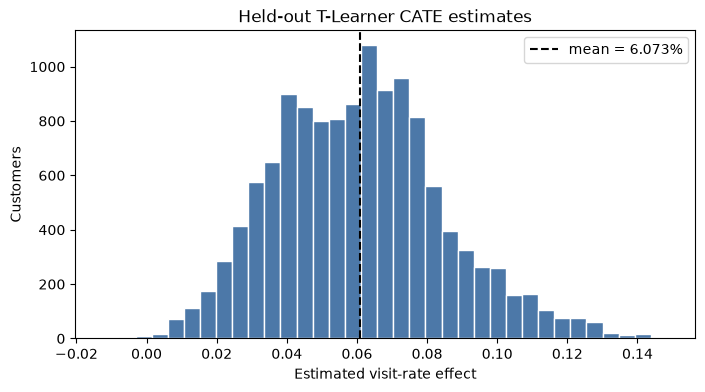

By recency quartile:


,customers,mean_cate,median_cate
recency_group,,,
"(0.999, 2.0]",3265,0.06649,0.06558
"(2.0, 5.0]",3171,0.05862,0.05973
"(5.0, 9.0]",3733,0.05870,0.05824
"(9.0, 12.0]",2631,0.05901,0.05951


By prior purchase channel:


,customers,mean_cate,median_cate
channel,,,
Multichannel,1508,0.06061,0.06086
Phone,5615,0.05890,0.05843
Web,5677,0.06258,0.06294


In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(cate, bins=35, color="#4C78A8", edgecolor="white")
ax.axvline(cate.mean(), color="black", linestyle="--", label=f"mean = {cate.mean():.3%}")
ax.set(title="Held-out T-Learner CATE estimates", xlabel="Estimated visit-rate effect", ylabel="Customers")
ax.legend(); plt.show()

test_results["recency_group"] = pd.qcut(test_results.recency, q=4, duplicates="drop")
print("By recency quartile:")
display(test_results.groupby("recency_group", observed=True).agg(customers=("cate","size"), mean_cate=("cate","mean"), median_cate=("cate","median")).round(5))
print("By prior purchase channel:")
display(test_results.groupby("channel", observed=True).agg(customers=("cate","size"), mean_cate=("cate","mean"), median_cate=("cate","median")).round(5))

## Held-out uplift evaluation

Individual treatment effects are unobserved, so no ITE accuracy score is calculated. The model ranks test customers by predicted CATE; uplift within ranked groups is estimated from randomized treated and control outcomes. The targeting budget is fixed at 30%. Confidence intervals below are descriptive Wald intervals.

,decile,n,treated_rate,control_rate,ATE_difference,CI_95_low,CI_95_high
0,1,1280,0.23873,0.14597,0.09276,0.04925,0.13628
1,2,1280,0.20887,0.11820,0.09066,0.04959,0.13174
2,3,1280,0.18109,0.10697,0.07413,0.03461,0.11365
3,4,1280,0.17375,0.11597,0.05778,0.01864,0.09692
4,5,1280,0.14116,0.08009,0.06107,0.02643,0.09571
5,6,1280,0.15808,0.11033,0.04775,0.00923,0.08627
6,7,1280,0.15465,0.08333,0.07132,0.03550,0.10713
7,8,1280,0.15385,0.11374,0.04010,0.00137,0.07884
8,9,1280,0.10400,0.05926,0.04474,0.01412,0.07537
9,10,1280,0.15977,0.12195,0.03782,-0.00213,0.07777


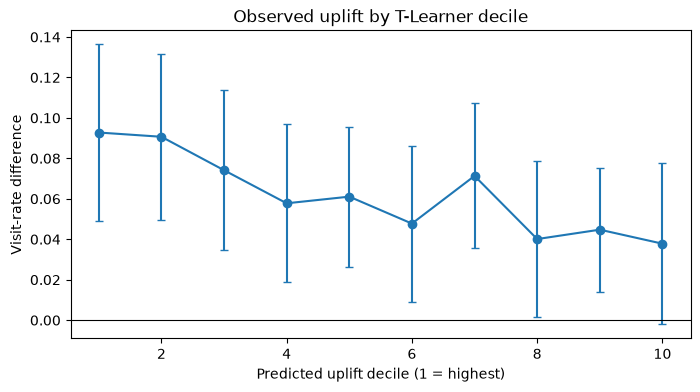

In [6]:
test_results["decile"] = pd.qcut(test_results.cate.rank(method="first", ascending=False), 10, labels=range(1, 11))
rows = []
for decile, part in test_results.groupby("decile", observed=True):
    est = difference_in_means(part.outcome, part.treatment)
    rows.append({"decile": int(decile), "n": len(part), **est.to_dict()})
deciles = pd.DataFrame(rows).sort_values("decile")
display(deciles[["decile","n","treated_rate","control_rate","ATE_difference","CI_95_low","CI_95_high"]].round(5))
fig, ax = plt.subplots(figsize=(8,4))
ax.errorbar(deciles.decile, deciles.ATE_difference,
    yerr=[deciles.ATE_difference-deciles.CI_95_low, deciles.CI_95_high-deciles.ATE_difference], fmt="o-", capsize=3)
ax.axhline(0,color="black",linewidth=.8); ax.set(title="Observed uplift by T-Learner decile",xlabel="Predicted uplift decile (1 = highest)",ylabel="Visit-rate difference"); plt.show()

AUUC: 454.242 | Qini coefficient: 40.784


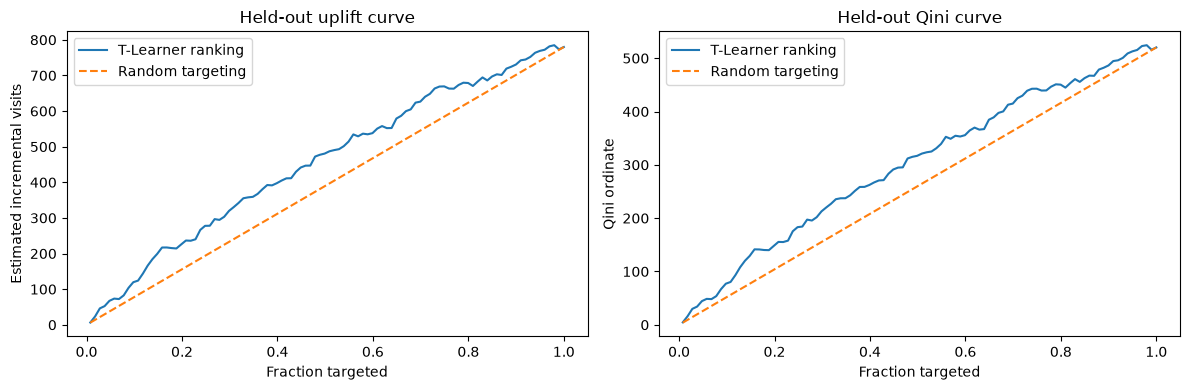

,strategy,n,treated_rate,control_rate,ATE_difference,CI_95_low,CI_95_high,estimated_incremental_visits
0,Target everyone,12800,0.1670,0.1061,0.0609,0.0488,0.0731,779.7772
1,Random 30% (expected),3840,0.1670,0.1061,0.0609,0.0488,0.0731,233.9332
2,Top predicted 30%,3840,0.2089,0.1246,0.0843,0.0603,0.1083,323.7488


In [7]:
ordered = test_results.sort_values("cate", ascending=False).reset_index(drop=True)
curve_rows = []
for k in np.unique(np.linspace(100, len(ordered), 100, dtype=int)):
    part = ordered.iloc[:k]
    nt, nc = (part.treatment == 1).sum(), (part.treatment == 0).sum()
    if nt and nc:
        uplift = part.loc[part.treatment == 1, "outcome"].mean() - part.loc[part.treatment == 0, "outcome"].mean()
        gain = k * uplift
        qini = part.loc[part.treatment == 1, "outcome"].sum() - (nt / nc) * part.loc[part.treatment == 0, "outcome"].sum()
        curve_rows.append([k/len(ordered), gain, qini])
curves = pd.DataFrame(curve_rows, columns=["fraction", "uplift_gain", "qini"])
random_gain = len(ordered) * test_baseline.ATE_difference * curves.fraction
random_qini = curves.qini.iloc[-1] * curves.fraction
auuc = auc(curves.fraction, curves.uplift_gain)
qini_coefficient = auc(curves.fraction, curves.qini-random_qini)
print(f"AUUC: {auuc:.3f} | Qini coefficient: {qini_coefficient:.3f}")
fig, axes = plt.subplots(1,2,figsize=(12,4))
axes[0].plot(curves.fraction,curves.uplift_gain,label="T-Learner ranking"); axes[0].plot(curves.fraction,random_gain,"--",label="Random targeting")
axes[0].set(title="Held-out uplift curve",xlabel="Fraction targeted",ylabel="Estimated incremental visits"); axes[0].legend()
axes[1].plot(curves.fraction,curves.qini,label="T-Learner ranking"); axes[1].plot(curves.fraction,random_qini,"--",label="Random targeting")
axes[1].set(title="Held-out Qini curve",xlabel="Fraction targeted",ylabel="Qini ordinate"); axes[1].legend()
plt.tight_layout(); plt.show()

budget = int(np.ceil(.30*len(test_results)))
top = test_results.nlargest(budget,"cate")
top_effect = difference_in_means(top.outcome,top.treatment)
comparison = pd.DataFrame([
 {"strategy":"Target everyone","n":len(test_results),**test_baseline.to_dict()},
 {"strategy":"Random 30% (expected)","n":budget,**test_baseline.to_dict()},
 {"strategy":"Top predicted 30%","n":budget,**top_effect.to_dict()},
])
comparison["estimated_incremental_visits"] = comparison.n*comparison.ATE_difference
display(comparison[["strategy","n","treated_rate","control_rate","ATE_difference","CI_95_low","CI_95_high","estimated_incremental_visits"]].round(4))

## Interpretation and limitations

Compare the model-based mean CATE with the randomized ATE, and assess whether the held-out ranking adds evidence beyond the average treatment effect. Segment and ranking estimates remain uncertain, particularly in smaller subsets. This single split does not establish deployment performance. Pooling email creatives estimates a mixed email policy, and results apply to this customer population and two-week window. The notebook's group-level confidence intervals do not account for uncertainty from fitting and ranking the model, so interpret them as descriptive. No individual counterfactual outcome is observed.